# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 2 (Trang 15-17) - Câu 5: Thống kê số người đi cùng và khảo sát sự liên quan với khả năng sống sót (survived)

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Thống kê đi một mình (1: Đi một mình, 0: Có người thân đi cùng):
not_alone
1    790
0    519
Name: count, dtype: int64

Số lượng hành khách theo số lượng người thân đi cùng (relatives):
relatives
0     790
1     235
2     159
3      43
4      22
5      25
6      16
7       8
10     11
Name: count, dtype: int64


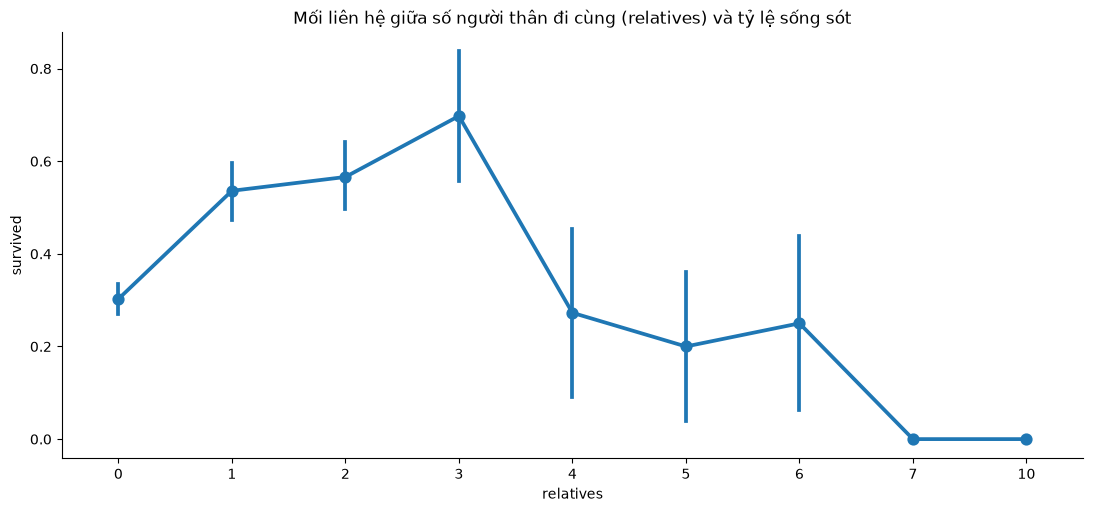

In [1]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (15-17) - Câu 5: Thống kê số người đi cùng và khảo sát sự liên quan với survived

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Đọc dữ liệu
def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join('..', rel_path),
        os.path.join('..', '..', rel_path),
        os.path.join('datasets', os.path.basename(rel_path)),
        os.path.join('..', 'datasets', os.path.basename(rel_path)),
        os.path.join('..', '..', 'datasets', os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f'Không tìm thấy file dữ liệu: {rel_path}')

csv_path = get_data_path('titanic.csv')
df = pd.read_csv(csv_path, na_values=['?'])
df.columns = df.columns.str.lower()
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['fare'] = pd.to_numeric(df['fare'], errors='coerce')

# Tạo thuộc tính tổng số người thân đi cùng (relatives) và đi một mình (not_alone)
df['relatives'] = df['sibsp'] + df['parch']
df.loc[df['relatives'] > 0, 'not_alone'] = 0  # Có người đi cùng
df.loc[df['relatives'] == 0, 'not_alone'] = 1 # Đi một mình
df['not_alone'] = df['not_alone'].astype(int)

# Thống kê số người đi một mình và có người đi cùng
print("Thống kê đi một mình (1: Đi một mình, 0: Có người thân đi cùng):")
print(df['not_alone'].value_counts())
print("\nSố lượng hành khách theo số lượng người thân đi cùng (relatives):")
print(df['relatives'].value_counts().sort_index())

# Vẽ biểu đồ quan hệ giữa relatives và survived
axes = sns.catplot(x='relatives', y='survived', data=df, aspect=2.2, kind='point')
plt.title("Mối liên hệ giữa số người thân đi cùng (relatives) và tỷ lệ sống sót")
def get_img_dir(subpath=''):
    for base in ['.', '..', '../..']:
        img_root = os.path.join(base, 'images')
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, 'datasets')) or os.path.exists(os.path.join(base, 'CLAUDE.md'))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join('images', subpath) if subpath else 'images'
    os.makedirs(target, exist_ok=True)
    return target

img_dir = get_img_dir('Phan1/Bai1')
plt.savefig(os.path.join(img_dir, 'titanic_relatives_survived.png'), dpi=300, bbox_inches='tight')
